<a href="https://colab.research.google.com/github/cdiegor/Metaheuristicas/blob/main/PCV_2026_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introdução

O problema do caixeiro viajante (PCV ou TSP) faz a seguinte pergunta: "dada uma lista de cidades e as distâncias entre cada par de cidades, qual é a rota mais curta possível que visita cada cidade exatamente uma vez e retorna à cidade de origem?" É um problema NP-difícil em otimização combinatória, importante em ciência da computação teórica e pesquisa operacional.

O problema do comprador viajante e o problema de roteamento de veículos são generalizações do PCV.

Na teoria da complexidade computacional, a versão de decisão do TSP (onde dado um comprimento L, a tarefa é decidir se o grafo tem um percurso de no máximo L) pertence à classe de problemas NP-completos. Assim, é possível que o tempo de execução do pior caso para qualquer algoritmo para o TSP aumente superpolinomialmente (mas não mais que exponencialmente) com o número de cidades.

O problema foi formulado pela primeira vez em 1930 e é um dos problemas mais intensamente estudados em otimização. Ele é usado como referência para muitos métodos de otimização. Embora o problema seja computacionalmente difícil, muitas heurísticas e algoritmos exatos são conhecidos, de modo que algumas instâncias com dezenas de milhares de cidades podem ser resolvidas completamente e mesmo problemas com milhões de cidades podem ser aproximados em uma pequena fração de 1% (o que dizer de um problema com todas as cidades do mundo? https://www.math.uwaterloo.ca/tsp/world/)

O PCV tem diversas aplicações mesmo em sua formulação mais pura, como planejamento, logística e fabricação de microchips. Ligeiramente modificado, aparece como um subproblema em muitas áreas, como no sequenciamento de DNA. Nessas aplicações, o conceito de cidade representa, por exemplo, clientes, pontos de solda ou fragmentos de DNA, e o conceito de distância representa tempo ou custo de viagem, ou uma medida de similaridade entre fragmentos de DNA. O PCV também aparece na astronomia, pois os astrônomos que observam muitas fontes desejam minimizar o tempo gasto movendo o telescópio entre as fontes; em tais problemas, o PCV pode ser inserido em um problema de controle ótimo. Em muitas aplicações, podem ser impostas restrições adicionais, como recursos limitados ou janelas de tempo.

Fonte: Wikipedia. *Travelling salesman problem*. Acessível em https://en.wikipedia.org/wiki/Travelling_salesman_problem

## Créditos

A maior parte dos códigos, ideias, figuras foram inspiradas ou obtidas de Jupyter at Bryn Mawr College, *The Traveling Salesperson Problem*. Acessível em https://jupyter.brynmawr.edu/services/public/dblank/jupyter.cs/FLAIRS-2015/TSPv3.ipynb

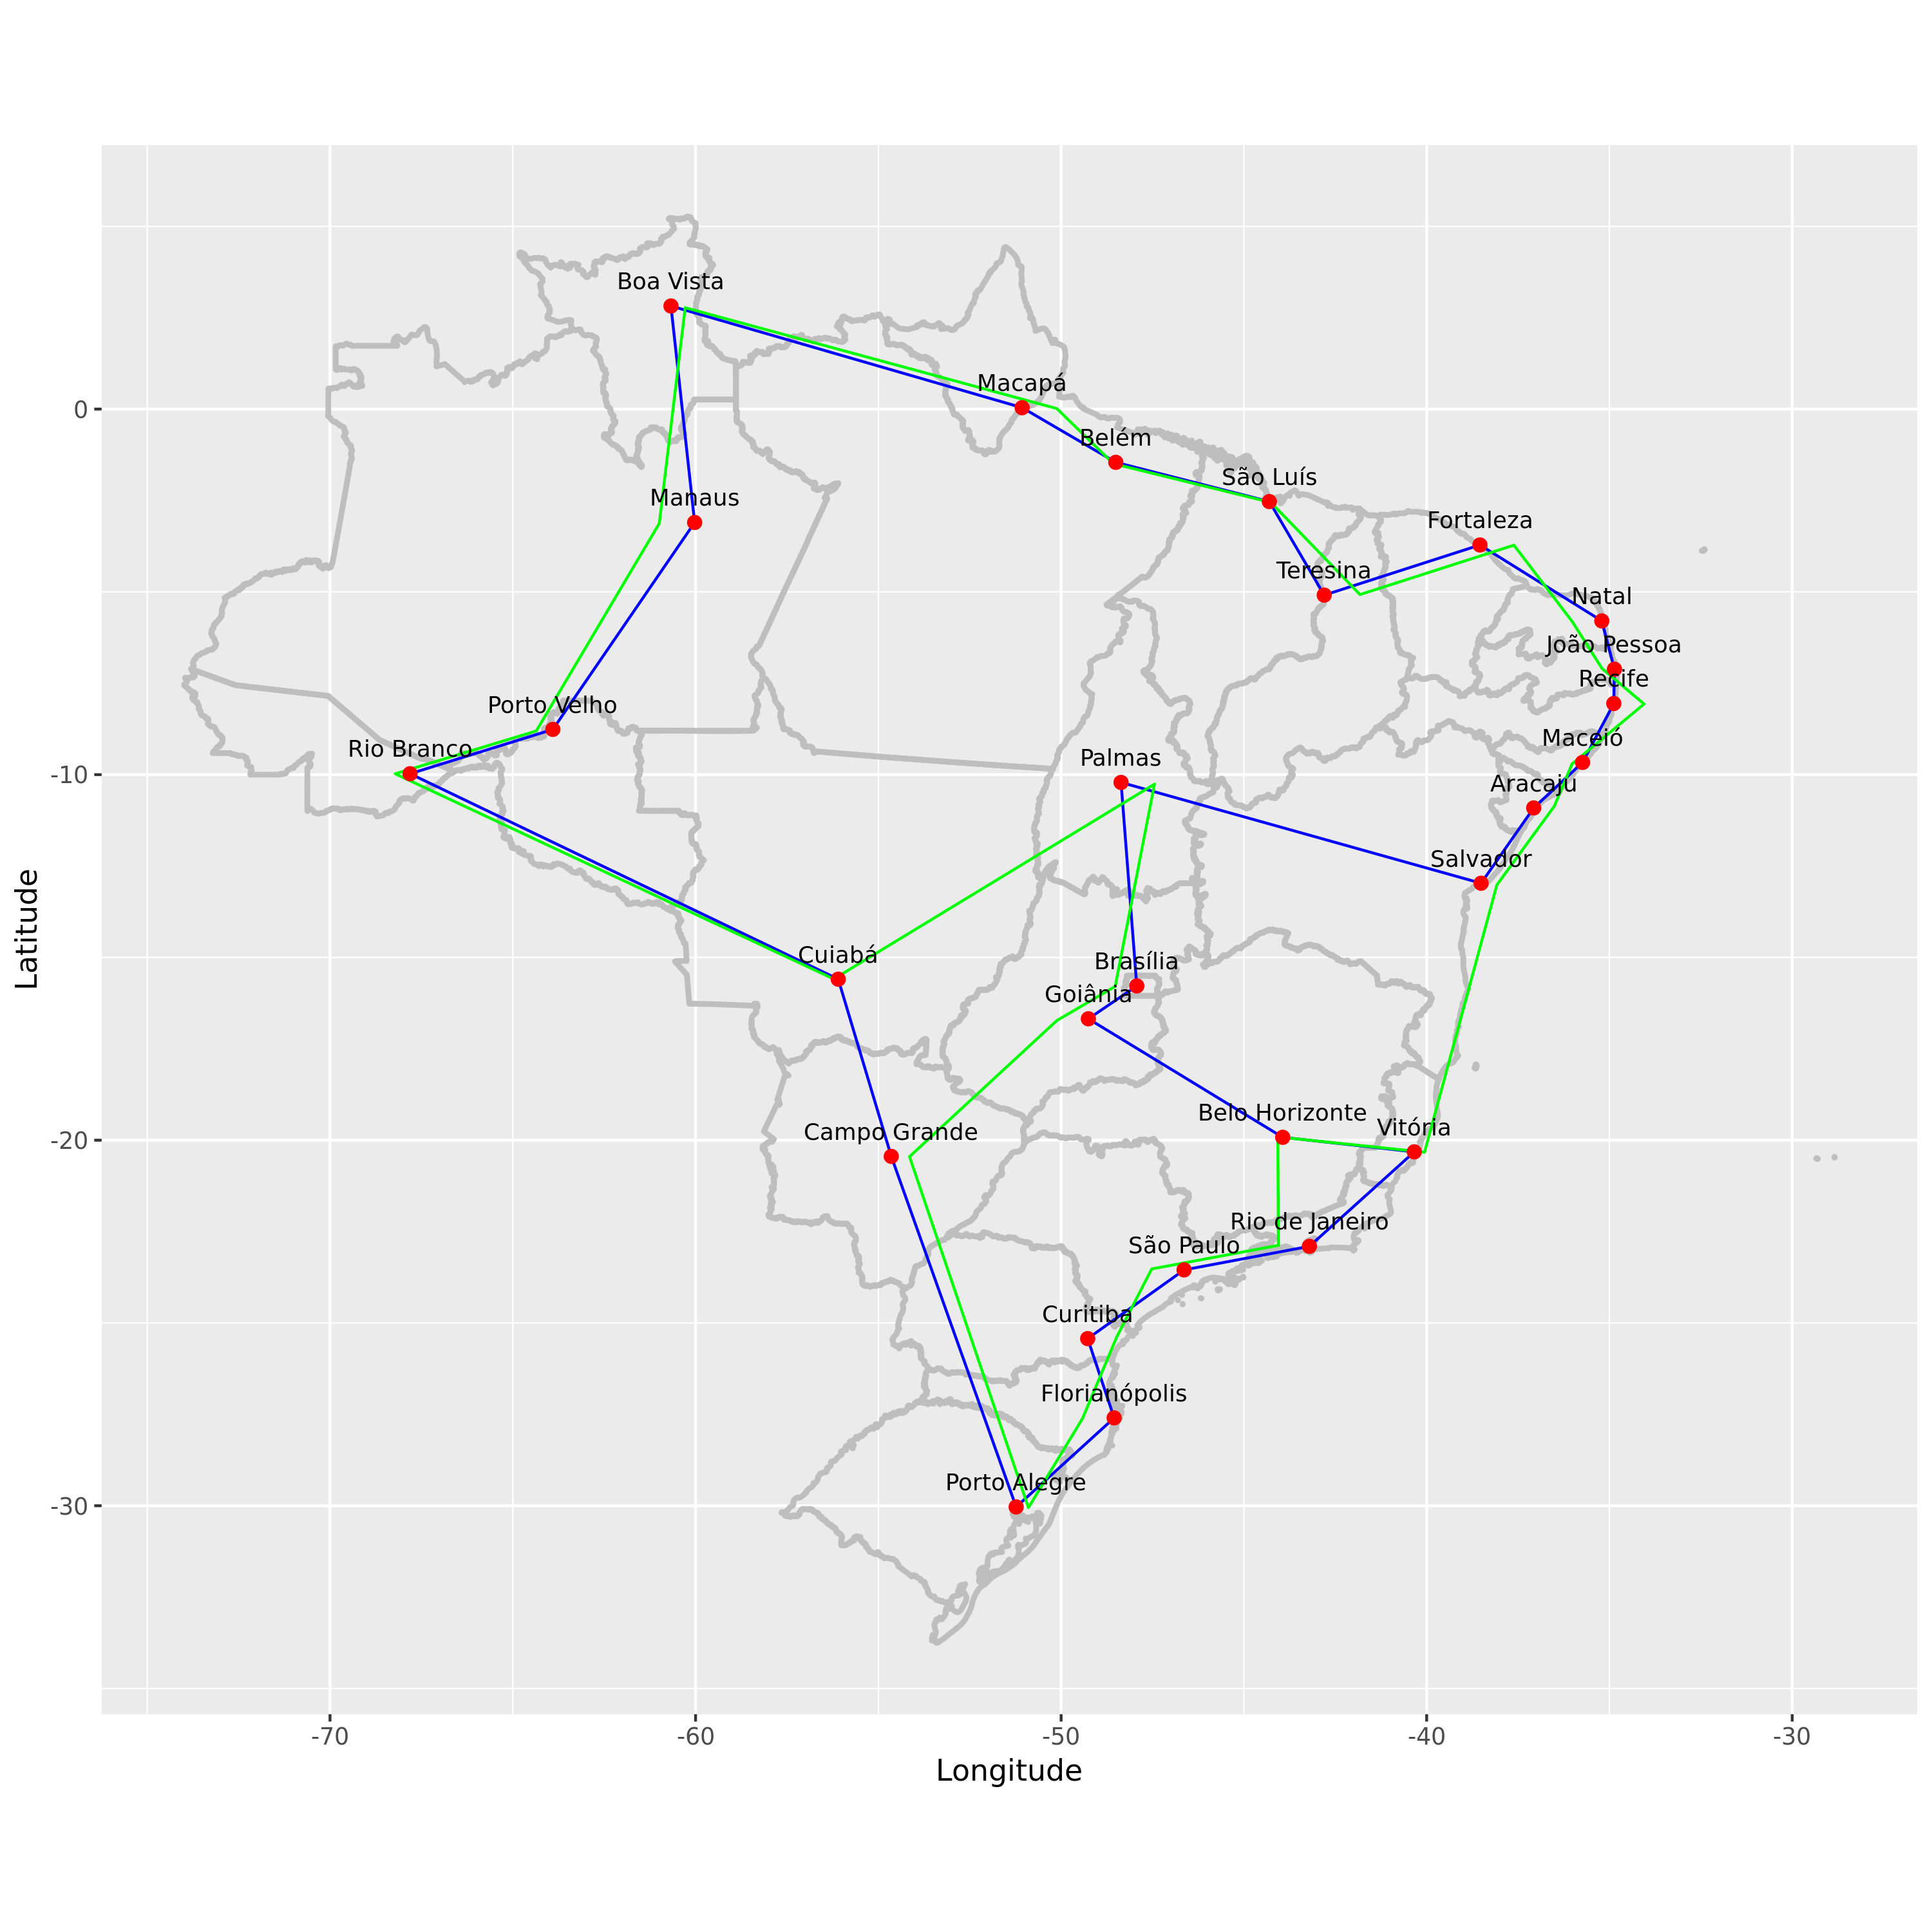

Fonte: Dan S. Reznik, *TSP for Brazilian State Capitals*. Acessível em https://github.com/dan-reznik/TSP-Brazilian-Capitals/blob/master/pics/tsp%20brazil%20ibge%20state%20polygons.png

# Todas as possíveis rotas

Embora saibamos que esta não é uma maneira prática de abordar casos com um número razoável de cidades, vamos começar com o algoritmo força bruta, ou seja, a enumeração de todas as possíveis rotas.

In [2]:
import matplotlib.pyplot as plt
import math
import random
import time
import itertools
import urllib
import csv

In [3]:
def forca_bruta(cidades):
    "Gera todas as possíveis rotas e escolhe a menor delas."
    return rota_mais_curta(todas_as_rotas(cidades))

def rota_mais_curta(rotas):
    "Escolhe a rota com menor tamanho."
    return min(rotas, key=tamanho_rota)

# TO DO: Tipos de dados: cidades, rotas, Funções: todas_as_rotas, tamanho_rota

**Detalhe**: no Python min(*conjunto, key=função*) significa achar o elemento que minimiza a função passada como chave.

## Representando uma rota

Uma rota pode ser representada por uma permutação das cidades a serem passadas. A ordem em que elas aparecem determina as distâncias a serem percorridas,pois duas cidades adjacentes representam um percurso.

In [4]:
todas_as_rotas = itertools.permutations

In [5]:
#Exemplo

cidades = [1, 2, 3, 4]
list(todas_as_rotas(cidades))

[(1, 2, 3, 4),
 (1, 2, 4, 3),
 (1, 3, 2, 4),
 (1, 3, 4, 2),
 (1, 4, 2, 3),
 (1, 4, 3, 2),
 (2, 1, 3, 4),
 (2, 1, 4, 3),
 (2, 3, 1, 4),
 (2, 3, 4, 1),
 (2, 4, 1, 3),
 (2, 4, 3, 1),
 (3, 1, 2, 4),
 (3, 1, 4, 2),
 (3, 2, 1, 4),
 (3, 2, 4, 1),
 (3, 4, 1, 2),
 (3, 4, 2, 1),
 (4, 1, 2, 3),
 (4, 1, 3, 2),
 (4, 2, 1, 3),
 (4, 2, 3, 1),
 (4, 3, 1, 2),
 (4, 3, 2, 1)]

In [6]:
def tamanho_rota(rota):
  "A distância total percorrida entre dois pares consecutivos em uma rota"
  return sum(distancia(rota[i-1], rota[i]) for i in range(len(rota)))

#TO DO: Função: distancia, Tipo de dados: cidades

**Detalhe**: Aqui usamos um truque específico do Python no qual

```
distancia(rota[-1], rota[0])
```

 se refere a distância entre o primeiro e o último elemento do vetor rota.

## Representando cidades

Cada cidade será representada como um ponto no espaço euclidiano $\mathbb{R}^2$ e a distância entre duas cidades é a distância euclidiana.

Neste caso temos um PCV simétrico, métrico, euclidiano.

Simétrico significa que a relação de distância é simétrica, ou seja: $\forall u, v \ : \ distancia(u,v) = distancia(v,u)$

Métrico significa que as distâncias obedecem desigualdades trianguelares, ou seja: $\forall u, v, w \ : \ distancia(u,v) \leq distancia(u, w) + distancia(w, v)$

E finalmente euclidiano significa que a distância euclidiana é a medida de distância utilizada. Essa definição é suficiente para as duas anteriores.




## Computando distâncias

No Python já temos a distância euclidiana disponível na biblioteca matemática, portanto vamos apenas renomeá-la por conveniência nos códigos a seguir:

In [7]:
distancia = math.dist

In [8]:
#Exemplo
A = [3, 0]
B = [0, 4]
print(distancia(A,B))

5.0


## Conjunto de cidades aleatórias

Para efeitos de nossos tester vamos considerar inicialmente a geração de instâncias aleatórias. Para isso vamos utilizar a geração de duplas que presentam as coordenadas euclidianas de cada cidade.

In [9]:
[ [random.randrange(1000), random.randrange(1000)] for c in range(7) ]

[[632, 299],
 [107, 834],
 [519, 774],
 [911, 923],
 [856, 67],
 [124, 285],
 [466, 905]]

Encapsulando isto em uma função e pensando nas dimensões da visualização, escrevemos a seguinte função de geração de uma instância aleatória.

In [10]:
def Cidades (n, largura=900, altura=600, rseed=233):
  "Faz um conjunto com n cidades, com coordenadas aleatórias no máximo (largura x alutura)"
  random.seed(rseed)
  return [ [random.randrange(largura), random.randrange(altura)] for c in range(n) ]

A seguir usamos a função de geração de um conjunto de 10 cidades e passamos para o algoritmo força bruta, cujo retorno a melhor rota para o caixeiro viajante, escrevendo uma sequência de coordenadas do espaço euclidiano, referentes à rota do caixeiro.

In [11]:
forca_bruta(Cidades(10))

([698, 178],
 [767, 291],
 [819, 495],
 [620, 232],
 [564, 209],
 [537, 236],
 [275, 239],
 [78, 243],
 [85, 104],
 [710, 14])

## Desenhando a solução

Para entender melhor o que se passa na solução apresentada pelos algoritmos vamos elaborar uma visualização simples da instância e da rota. Caso o parâmetro "completa" seja verdadeiro, vamos imprimir as arestas entre qualquer par de vértices.

In [12]:
def plot_rota(rota, completa=True):
  x = []
  y = []
  for i in range(len(rota)):
    x.append(rota[i][0])
    y.append(rota[i][1])

  if (completa):
    for i in range(len(rota)-1):
      for j in range(i+1,len(rota)):
        plt.plot([x[i], x[j]], [y[i], y[j]], color="LightGray", linewidth=1)

  for i in range(len(rota)):
    plt.plot([x[i], x[i-1]], [y[i], y[i-1]], color="Red", linewidth=2)

  plt.scatter(x, y, color="Blue", linewidth=3)

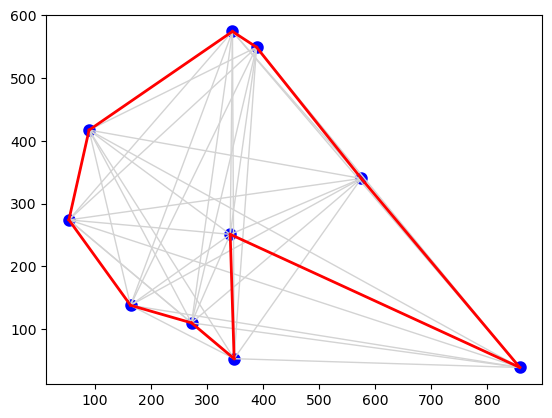

In [13]:
plot_rota(forca_bruta(Cidades(10, rseed=123)))

## Complexidade de enumerar todas as rotas
Demora cerca de 2 segundos na minha máquina para resolver este problema de 10 cidades. Em geral, a função TSP considera (n-1)! passeios para um problema de n cidades, e cada passeio tem n cidades, então o tempo total necessário para n cidades deve ser aproximadamente proporcional a n!. Isso significa que o tempo cresce rapidamente com o número de cidades. Realmente rapidamente. Esta tabela mostra o tempo real para resolver um problema de 10 cidades e o tempo esperado para resolver problemas maiores:



> |n	|tempo esperado
  |:- |:-
  |10	|10! rotas = 2 seg|
  |11	|2 seg × 11! / 10! ≈ 22 seg|
  |12	|2 seg × 12! / 10! ≈ 4 min|
  |14	|2 seg × 14! / 10! ≈ 13 horas|
  |16	|2 seg × 16! / 10! ≈ 200 dias|
  |18	|2 seg × 18! / 10! ≈ 112 anos|
  |25	|2 seg × 25! / 10! ≈ 270 bilhões de anos


Vamos precisar de uma forma melhor...

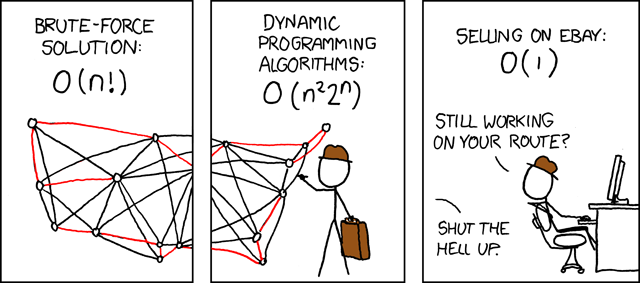

Fonte: Randall Munroe. *Travelling Salesman Problem*. Acessível em https://xkcd.com/399/

# Heurísticas construtivas

E se estivermos dispostos a nos contentar com um passeio curto, mas sem garantia de ser o mais curto? Então, podemos economizar bilhões de anos de tempo de computação: mostraremos algoritmos aproximados, que encontram passeios que normalmente estão dentro de 10% do passeio mais curto possível e podem lidar com milhares de cidades em poucos segundos. (Observação: existem algoritmos aproximados mais sofisticados que podem lidar com centenas de milhares de cidades e chegar a 0,01% ou mais do passeio mais curto possível.)

Então, como chegamos a um algoritmo aproximado? Aqui estão dois planos gerais de como criar um tour:



*   **Algoritmo do vizinho mais próximo**: Faz o tour ir de uma cidade até sua vizinha mais próxima. Repita.
*   **Algoritmo guloso**: Encontre a distância mais curta entre quaisquer duas cidades e inclua essa aresta no passeio sem formar trevos ou subciclos. Repita.         






Vamos expandir essas ideias em algoritmos completos.


## Vizinho mais próximo

Uma heurística construtiva que surge como uma primeira ideia é a seguinte: a partir de uma nó inicial, escolher para qual nó ir em seguida simplesmente selecionando o trajeto mais curto.

Esta é uma estratégia gulosa, pois a cada instante em que uma decisão precisa ser tomada para a construção da rota, o critério de otimização é usado sem que haja posteriormente uma reconsideração sobre aquela decisão.


In [14]:
def vizinho_mais_proximo(cidades):
    """Comece a rota na primeira cidade; a cada passo estenda a rota
    movendo-se da cidade anterior para a vizinha mais próxima
    que ainda não foi visitada."""
    primeira = cidades[0]
    rota = [primeira]
    inexploradas = cidades.copy()
    inexploradas.remove(primeira)
    while inexploradas:
        C = mais_proxima(rota[-1], inexploradas)
        rota.append(C)
        inexploradas.remove(C)
    return rota

def mais_proxima(c, cidades):
    "Encontre a cidade mais próxima da cidade c."
    return min(cidades, key=lambda x: distancia(c, x))

Detalhe: Em Python, assim como na teoria da computação, lambda (ou λ) é o símbolo para função, então "lambda x: distancia(c, x)" significa a função de x que calcula a distância de x para a cidade c.

Podemos comparar o rápido (porém inexado) algoritmo de vizinho mais próximo ao lento (porém exato) algoritmo de enumeração de todas as rotas para um conjunto pequeno:

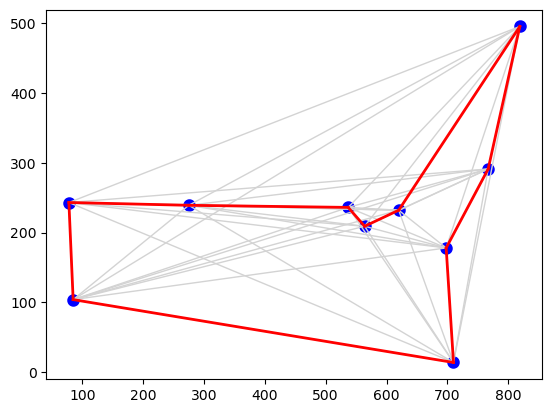

In [15]:
plot_rota(forca_bruta(Cidades(10)))

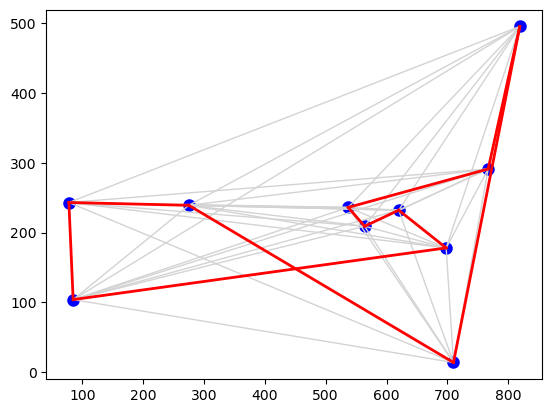

In [16]:
plot_rota(vizinho_mais_proximo(Cidades(10)))

In [17]:
Cidades(10)

[[698, 178],
 [537, 236],
 [819, 495],
 [564, 209],
 [85, 104],
 [275, 239],
 [710, 14],
 [78, 243],
 [620, 232],
 [767, 291]]

Outra forma de compara é saber a qual a distância percentual da melhor solução obtida para a solução ótima dada pelo algoritmo que enumera todas as rotas. Essa distância é conhecida como *gap*.

In [18]:
def gap(cidades):
    "Gap percentual entre o algoritmo de vizinho mais próximo e o algoritmo de todas as rotas."
    opt = tamanho_rota(forca_bruta(cidades))
    cnd = tamanho_rota(vizinho_mais_proximo(cidades))
    return  (cnd-opt)/opt

Para um resultado mais confiável podemos rodar um número maior de vezes.

In [19]:
gaps = sorted(gap(Cidades(10, rseed=i)) for i in range(10))
[ print("{0:0.2f}".format(x)) for x in gaps ]
mean = sum(gaps)/len(gaps)
print("Media = ", "{0:0.2f}".format(mean))
print("Desvio Padrão = ", "{0:0.2f}".format( ( sum([((x - mean) ** 2) for x in gaps]) / len(gaps) ) **0.5 ) )

0.00
0.00
0.00
0.15
0.19
0.20
0.23
0.24
0.25
0.29
Media =  0.15
Desvio Padrão =  0.11


Sabemos que é pior, mas podemos agora dar respostas para uma entrada com centenas ou milhares de cidades.

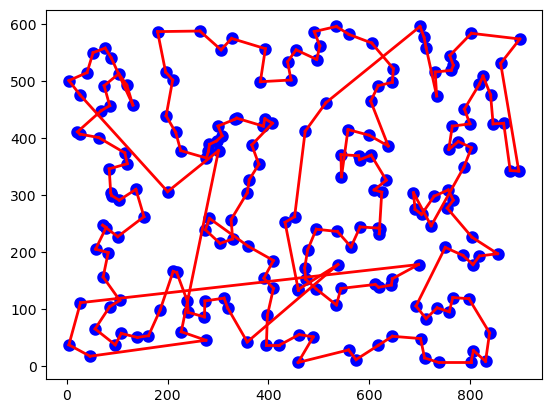

In [20]:
plot_rota(vizinho_mais_proximo(Cidades(200)),completa=False)

### Resultados podem variar dependendo do ponto de partida

A cidade inicial escolhida define toda a sequência de decisões que serão tomadas. Ao mudarmos a cidade inicial, é possível observar leves variações sobre a rota utilizada. Vamos então definir um algoritmo em que é possível selecionar o ponto de partida e avaliar como isso pode variar.

In [21]:
def vmp(cidades, inicio):
    """Comece a rota na primeira cidade; a cada passo estenda a rota
    movendo-se da cidade anterior para a vizinha mais próxima
    que ainda não foi visitada."""
    primeira = cidades[inicio]
    rota = [primeira]
    inexploradas = cidades.copy()
    inexploradas.remove(primeira)
    while inexploradas:
        C = mais_proxima(rota[-1], inexploradas)
        rota.append(C)
        inexploradas.remove(C)
    return rota


Se quisermos obter o melhor valor possível com essa heurística podemos executá-la para todos as cidades como ponto inicial.

In [22]:
def vmp_completa(cidades):
  return rota_mais_curta([ vmp(cidades, i) for i in range(len(cidades))])


A seguir vamos fazer comparações com as rotas geradas a partir de pontos diferentes e a melhor rota possível com esta estratégia.

Tamanho =  10799.126338818005


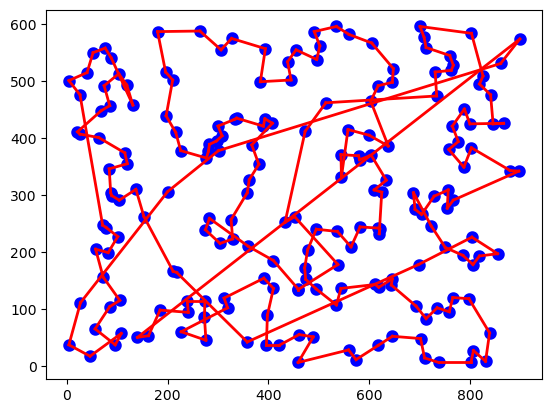

In [23]:
rota = vmp(Cidades(200), 122)
print("Tamanho = ", tamanho_rota(rota) )
plot_rota(rota,completa=False)

Tamanho =  10226.428015396954


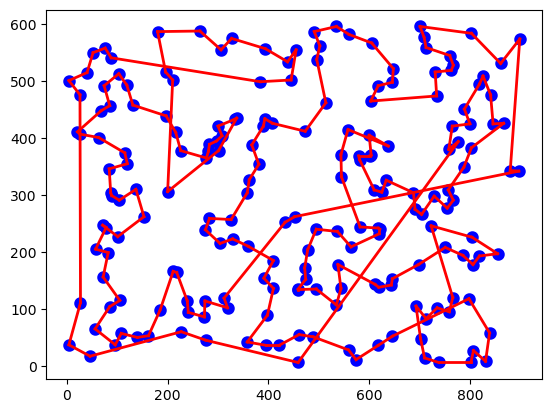

In [24]:
rota = vmp(Cidades(200), 78)
print("Tamanho = ", tamanho_rota(rota) )
plot_rota(rota,completa=False)

Tamanho =  9947.59311490794


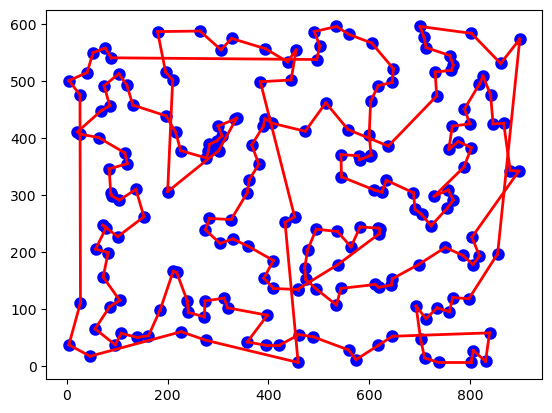

In [25]:
rota = vmp(Cidades(200), 13)
print("Tamanho = ", tamanho_rota(rota) )
plot_rota(rota,completa=False)

Tamanho =  9348.6722200493


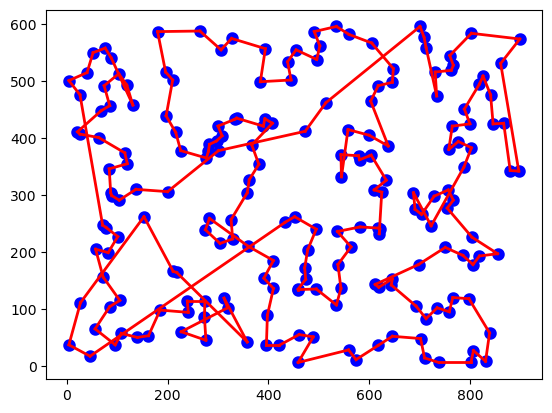

In [26]:
rota = vmp_completa(Cidades(200))
print("Tamanho = ", tamanho_rota(rota) )
plot_rota(rota,completa=False)

### Caso ruim: outliers

É possível construir casos onde a estratégia de partir de uma cidade para a mais próxima acaba gerando uma sobrecarga muito grande para as cidades deixadas para o final da rota.

Um exemplo pode ser visto a seguir.

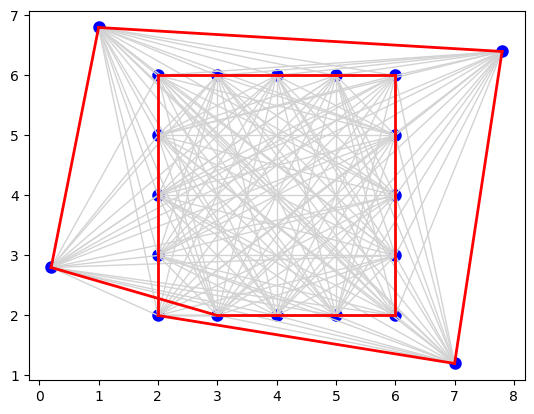

In [27]:
outliers = [[2, 2],  [2, 3],  [2, 4],  [2, 5],  [2, 6],
                 [3, 6],  [4, 6],  [5, 6],  [6, 6],
                 [6, 5],  [6, 4],  [6, 3],  [6, 2],
                 [5, 2],  [4, 2],  [3, 2],
                 [1, 6.8],  [7.8, 6.4],  [7, 1.2],  [0.2, 2.8]]

plot_rota(vizinho_mais_proximo(outliers))

## Heurística gulosa para o PCV

Uma possibilidade para superar a "miopia" das escolhas locais seria olhar para todas as arestas do grafo antes de tomar uma decisão. Neste sentido a heurística gulosa trabalha com o conjunto de todas as arestas e em ordem crescente de distância verifica se ela pode ser incluída na rota, sem que isto forme trevos ou subciclos.

De fato o algoritmo vai trabalha com um vetor que indica para cada vértice se ele pode se conectar a um outro vértice. Isto só é possível se estes candidatos a uma conexão forem nós terminais dos segmentos que compomos no processo de construção da rota. Guardamos portanto o segmento para qual cada vértica é um terminal. Note que inicialmente todos são terminais de um segmento unitário.

In [28]:
def guloso(cidades, verbose=False):
    """Percorre todas as arestas em ordem crescente e escolhe a primeira
        possível para fazer parte da solução"""
    arestas = ordena_arestas(cidades)
    terminais = [ [c] for c in range(len(cidades)) ] # A dict of {endpoint: segment}
    for [u,v] in arestas:
        if terminais[u] != [] and terminais[v] != [] and terminais[u] != terminais[v]:
            rota = unir(terminais, u, v, verbose)
            if len(rota) == len(cidades):
                rota = [ cidades[rota[i]] for i in range(len(cidades)) ]
                return rota

# TO DO: functions: ordena_arestas, unir

As arestas no algoritmo anterior são visitadas em ordem de tamanho. Para ordená-las utilizamos o código a seguir.

In [29]:
def ordena_arestas(cidades):
  "Retorna todas as arestas em uma lista ordenada pelo tamanho."
  arestas = [ [u, v] for u in range(len(cidades)) for v in range(len(cidades)) if u < v]
  return sorted(arestas, key=lambda aresta : distancia(cidades[aresta[0]], cidades[aresta[1]]))

Uma vez que identificamos uma aresta que conecta segmentos distintos pelos seus nós terminais, fazemos apelo a função unir definida abaixo para atualizar a lista de terminais.

In [30]:
def unir(terminais, u, v, verbose=False):
    "Une o segmento de u ao segmento de v, mantendo o vetor de terminais"
    useg, vseg = terminais[u], terminais[v]
    if (verbose) : print(useg, "(+) ", vseg, " => ", end='')
    if useg[-1] is not u: useg.reverse()
    if vseg[0] is not v: vseg.reverse()
    useg.extend(vseg)
    if (verbose) : print(useg)
    terminais[u] = []
    terminais[v] = []
    terminais[useg[0]] = terminais[useg[-1]] = useg
    return useg

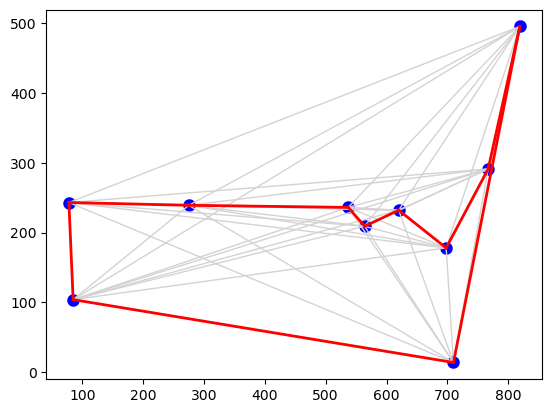

In [31]:
plot_rota(guloso(Cidades(10)))

A seguir observamos o desempenho do método, ligeiramente melhorado, para o caso dos outliers.

[0] (+)  [1]  => [0, 1]
[0, 1] (+)  [15]  => [1, 0, 15]
[1, 0, 15] (+)  [2]  => [15, 0, 1, 2]
[15, 0, 1, 2] (+)  [3]  => [15, 0, 1, 2, 3]
[15, 0, 1, 2, 3] (+)  [4]  => [15, 0, 1, 2, 3, 4]
[15, 0, 1, 2, 3, 4] (+)  [5]  => [15, 0, 1, 2, 3, 4, 5]
[15, 0, 1, 2, 3, 4, 5] (+)  [6]  => [15, 0, 1, 2, 3, 4, 5, 6]
[15, 0, 1, 2, 3, 4, 5, 6] (+)  [7]  => [15, 0, 1, 2, 3, 4, 5, 6, 7]
[15, 0, 1, 2, 3, 4, 5, 6, 7] (+)  [8]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8] (+)  [9]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9] (+)  [10]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10] (+)  [11]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] (+)  [12]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] (+)  [13]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13] (+)  [14]  => [15, 0,

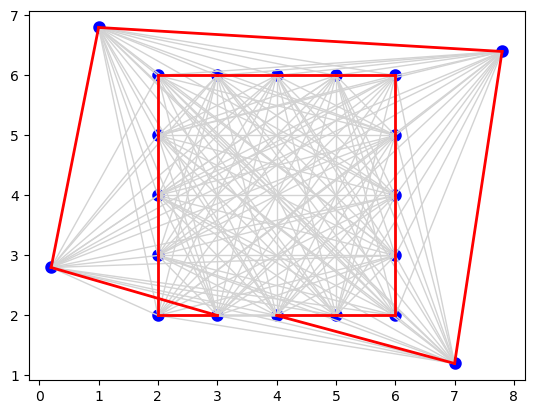

In [32]:
outliers = [[2, 2],  [2, 3],  [2, 4],  [2, 5],  [2, 6],
                 [3, 6],  [4, 6],  [5, 6],  [6, 6],
                 [6, 5],  [6, 4],  [6, 3],  [6, 2],
                 [5, 2],  [4, 2],  [3, 2],
                 [1, 6.8],  [7.8, 6.4],  [7, 1.2],  [0.2, 2.8]]

plot_rota(guloso(outliers, verbose=True))

## Procedimento de lapidação

Um dos ingredientes fundamentais para o funcionamento das metaheurísticas de trajetória é conseguir, a partir de uma solução, fazer ajustes para obter uma nova solução. Este processo de modificação é onipresente nesse tipo de heurística.

Aqui propomos uma modificação em que tomamos duas arestas $(u,v)$ e $(x,y)$ pertencentes a uma solução e propomos uma nova solução com as arestas $(u, x)$ e $(v, y)$. Para que isto seja possível também é preciso reverter (sem alteração de custo, já que estamos no caso simétrico) o caminho de $x$ para $y$ ou de $u$ para $v$

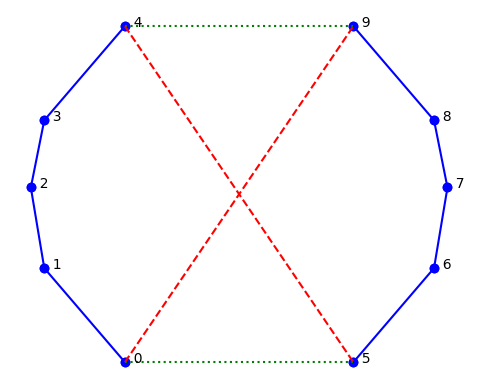

In [33]:
def plot_linhas(cidades, style='bo-'):
    "Plot lines to connect a series of points."
    x = [ p[0] for p in cidades ]
    y = [ p[1] for p in cidades ]
    plt.plot(x, y, style)
    plt.axis('scaled'); plt.axis('off')

def plot_nomes_linhas(cidades, *args):
    plot_linhas(cidades, 'bo')
    for (label, p) in enumerate(cidades):
        plt.text(p[0], p[1], '  '+str(label))
    # Draw lines indicated by args
    style = 'bo-'
    for arg in args:
        if isinstance(arg, str):
            style = arg
        else: # arg is a list of indexes into points, forming a line
            Xs = [cidades[i][0] for i in arg]
            Ys = [cidades[i][1] for i in arg]
            plt.plot(Xs, Ys, style)
    plt.axis('scaled'); plt.axis('off'); plt.show()

cross = [ [9, 3],  [3, 10],  [2, 16],  [3, 21],  [9, 28],
         [26, 3], [32, 10], [33, 16], [32, 21], [26, 28] ]

plot_nomes_linhas(cross, 'bo-', range(5), range(5, 10),
                          'g:', (4, 9), (0, 5),
                          'r--', (4, 5), (0, 9))

In [34]:
def reverter(rota, i, j):
    "Se a reversão da rota [i:j] for mais curta então reverta."
    u, v, x, y = rota[i-1], rota[i], rota[j-1], rota[j % len(rota)]
    if distancia(u, v) + distancia(x, y) > distancia(u, x) + distancia(v, y):
        rota[i:j] = reversed(rota[i:j])

A seguir escrevemos um algoritmo que passa por todos os seguimentos da rota e verifica se é vantajoso alterar a rota.

In [35]:
def alterar_rota(rota):
    "Procura todas as possíveis reversões de segmentos"
    segmentos = todos_segmentos(len(rota))
    while True:
      tamanho_atual = tamanho_rota(rota)
      for (u, v) in segmentos:
        reverter(rota, u, v)
      if tamanho_rota(rota) >= tamanho_atual: break
    return rota

def todos_segmentos(n):
    "Retorna todos os pares que formam segmentos de caminho numa rota de tamanho n."
    return [(u, u + t)
            for t in range(n, 1, -1)
            for u in range(n - t + 1)]

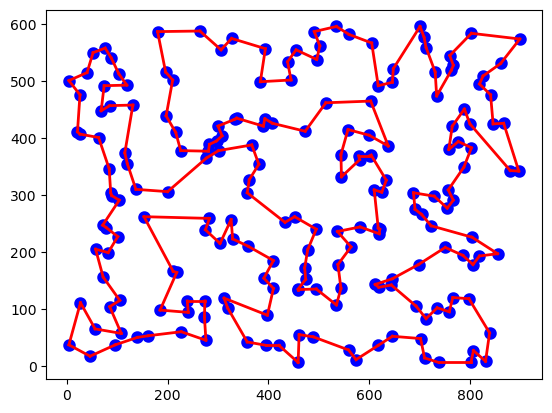

In [36]:
plot_rota(alterar_rota(vmp_completa(Cidades(200))), completa=False)

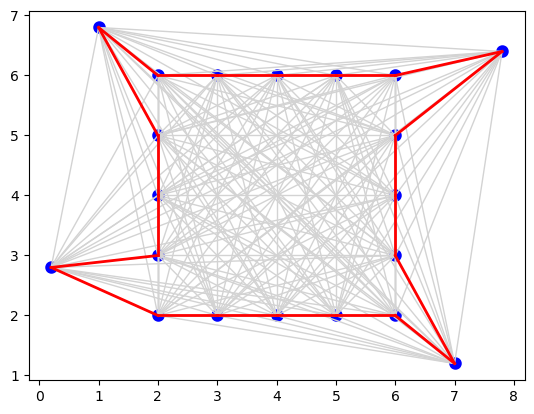

In [37]:
outliers = [[2, 2],  [2, 3],  [2, 4],  [2, 5],  [2, 6],
                 [3, 6],  [4, 6],  [5, 6],  [6, 6],
                 [6, 5],  [6, 4],  [6, 3],  [6, 2],
                 [5, 2],  [4, 2],  [3, 2],
                 [1, 6.8],  [7.8, 6.4],  [7, 1.2],  [0.2, 2.8]]

plot_rota(alterar_rota(guloso(outliers)))

# Exercícios

## Exercício 1 — Vizinho mais próximo com múltiplos pontos de partida

A heurística de vizinho mais próximo depende da cidade escolhida como ponto inicial. Já verificamos que executar o método para todos os possíveis pontos iniciais, como em `vmp_completa`, pode melhorar a qualidade da solução, mas também aumenta o custo computacional.

Implemente uma função

```python
vmp_amostral(cidades, proporcao=0.10, rseed=None)
```

que:

1. selecione aleatoriamente uma amostra contendo aproximadamente `proporcao × n` cidades;
2. utilize essas cidades como possíveis pontos iniciais;
3. execute a heurística de vizinho mais próximo para cada uma delas;
4. retorne a melhor rota encontrada.

Compare os seguintes métodos:

* `vmp`, utilizando apenas um ponto inicial;
* `vmp_amostral`, utilizando 10% das cidades como pontos iniciais;
* `vmp_completa`, utilizando todas as cidades como pontos iniciais.

Realize experimentos para diferentes tamanhos de instância, por exemplo:

$$
n \in \{50,100,200,500\}.
$$

Para cada método, registre:

* o valor da solução encontrada;
* o tempo de execução;
* a melhoria em relação à execução simples do vizinho mais próximo.

Sempre que possível, repita o experimento para diferentes instâncias aleatórias.

**Questões para discussão:**

1. Quanto ganhamos em qualidade utilizando vários pontos iniciais?
2. O ganho aumenta proporcionalmente ao número de pontos iniciais utilizados?
3. O aumento do custo computacional é compensado pela melhoria da solução?
4. Uma amostra de 10% parece suficiente? Experimente também outras proporções.

In [38]:
def vmp_amostral(cidades, proporcao=0.10, rseed=None):
    n = len(cidades)
    random.seed(rseed)

    # 1. Obtendo amostra aleatória de cidades
    amostra_qtd = math.floor(proporcao * n)
    amostra = random.sample(range(len(cidades)), amostra_qtd)

    # 2. Fazer as cidades da amostra serem pontos iniciais
    # 3. Rodar o vmp para cada cidade na amostra como ponto inicial
    # 4. Escolher a mais curta
    return rota_mais_curta([ vmp(cidades, i) for i in amostra ])


In [66]:
def comparar_valores(tempos={},valores={}):
    color_valor = "green" if valores['vmp_amostral'] < valores['vmp'] else "red"
    color_tempo = "green" if tempos['vmp_amostral'] < tempos['vmp'] else "red"

    fig, ax = plt.subplots(figsize=(6, 1.5))
    ax.axis("off")

    table = ax.table(
        cellText=[
            ["Temp. Execução", f"{tempos['vmp']:.6f} s", f"{tempos['vmp_completa']:.6f} s", f"{tempos['vmp_amostral']:.6f} s", f"{( ((tempos['vmp'] - tempos['vmp_amostral']) * 100) / tempos['vmp'] ):.2f} %"],
            ["Valor", valores['vmp'], valores['vmp_completa'], valores['vmp_amostral'], f"{( ((valores['vmp'] - valores['vmp_amostral']) * 100) / valores['vmp'] ):.2f} %"]
        ],
        colLabels=["", "VMP", "VMP Completa", "VMP Amostral", "Melhoria"],
        cellLoc="center",
        loc="center"
    )

    # Highlight the last value
    table[(1, 3)].set_facecolor(color_tempo)
    table[(1, 3)].get_text().set_color("white")
    table[(2, 3)].set_facecolor(color_valor)
    table[(2, 3)].get_text().set_color("white")

    # Style the table
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(2.0, 2.5)

    plt.show()

In [40]:
# Testando vmp_amostral
print( vmp_amostral(Cidades(687), proporcao=0.1, rseed=477) )

[[509, 205], [516, 225], [537, 236], [540, 208], [551, 194], [559, 193], [564, 209], [564, 217], [577, 212], [603, 204], [616, 215], [620, 232], [621, 240], [618, 242], [609, 245], [601, 248], [608, 260], [582, 244], [559, 278], [554, 282], [539, 272], [507, 266], [484, 279], [452, 262], [433, 252], [439, 240], [445, 237], [448, 219], [446, 198], [441, 195], [441, 168], [458, 159], [458, 156], [474, 152], [472, 172], [468, 196], [478, 204], [482, 214], [495, 240], [529, 189], [538, 178], [569, 158], [562, 136], [544, 136], [542, 128], [535, 107], [537, 68], [540, 65], [539, 44], [559, 28], [574, 11], [583, 40], [571, 59], [613, 60], [618, 36], [637, 10], [626, 1], [646, 52], [673, 37], [702, 48], [707, 33], [725, 29], [738, 39], [738, 6], [710, 14], [713, 83], [697, 106], [693, 105], [673, 90], [680, 78], [659, 126], [659, 138], [644, 142], [646, 153], [643, 159], [637, 172], [642, 178], [644, 185], [629, 178], [627, 175], [612, 143], [619, 138], [625, 133], [629, 139], [643, 124], [63

In [79]:
# Definindo cidades
cidades100 = Cidades(50)
cidades100 = Cidades(100)
cidades200 = Cidades(200)
cidades1000 = Cidades(500)

# Definindo proporcionalidade padrão para vmp_amostral
proporcao_padrao = 0.1

# Definindo rseed padrão
rseed_padrao = 578
# rseed_padrao = 389
# rseed_padrao = 298
# rseed_padrao = 165

def comparador(cidades=[], proporcao=0.1, seed=None):
    # VMP
    
    random.seed(seed)
    cidade_inicial = random.choice( range(len(cidades)) )

    inicio = time.perf_counter()

    rota_vmp = vmp(cidades, cidade_inicial)

    duracao_vmp = time.perf_counter() - inicio

    print("######### VMP #########")
    print(f"Tempo de execução: {duracao_vmp:.6f} s")
    print("Tamanho = ", tamanho_rota(rota_vmp) )
    plt.figure()
    plot_rota(rota_vmp, completa=False)
    plt.show()

    ## VMP Completa

    inicio = time.perf_counter()

    rota_vmp_completa = vmp_completa(cidades)

    duracao_vmp_completa = time.perf_counter() - inicio

    print("######### VMP Completa #########")
    print(f"Tempo de execução: {duracao_vmp_completa:.6f} s")
    print("Tamanho = ", tamanho_rota(rota_vmp_completa) )
    plt.figure()
    plot_rota(rota_vmp_completa, completa=False)
    plt.show()


    ## VMP Amostral

    inicio = time.perf_counter()

    rota_vmp_amostral = vmp_amostral(cidades, proporcao, seed)

    duracao_vmp_amostral = time.perf_counter() - inicio

    print("######### VMP Amostral #########")
    print(f"Tempo de execução: {duracao_vmp_amostral:.6f} s")
    print("Tamanho = ", tamanho_rota(rota_vmp_amostral) )
    plt.figure()
    plot_rota(rota_vmp_amostral, completa=False)
    plt.show()

    tempos = {
        'vmp': duracao_vmp, 
        'vmp_completa': duracao_vmp_completa, 
        'vmp_amostral': duracao_vmp_amostral
    }

    valores = {
        'vmp': tamanho_rota(rota_vmp), 
        'vmp_completa': tamanho_rota(rota_vmp_completa), 
        'vmp_amostral': tamanho_rota(rota_vmp_amostral)
    }

    comparar_valores(tempos, valores)

######### VMP #########
Tempo de execução: 0.000200 s
Tamanho =  4599.72573169094


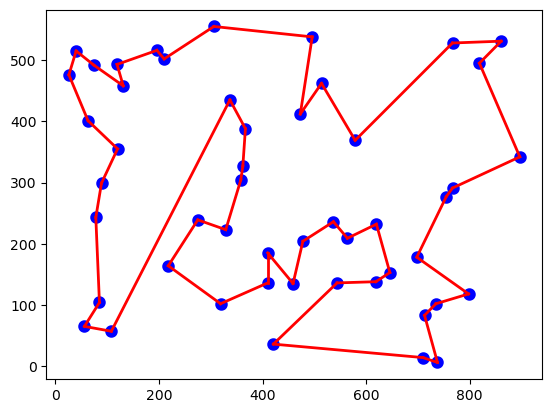

######### VMP Completa #########
Tempo de execução: 0.008890 s
Tamanho =  4522.014356949382


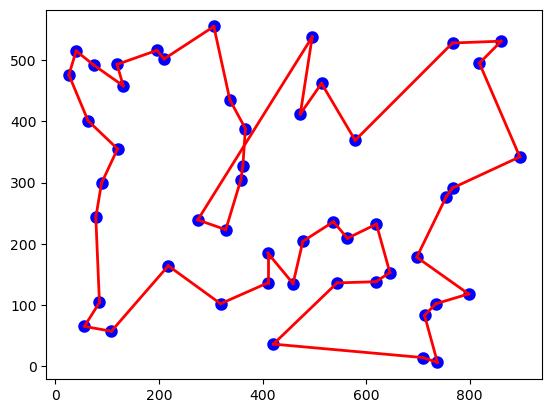

######### VMP Amostral #########
Tempo de execução: 0.001098 s
Tamanho =  4599.72573169094


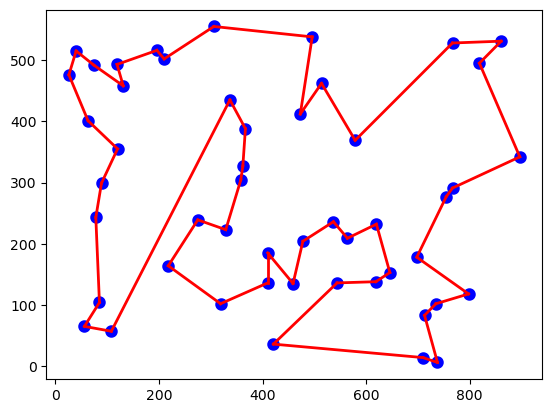

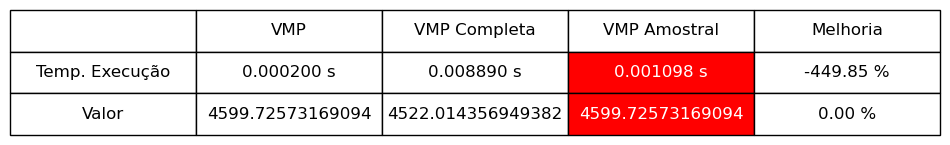

In [80]:
# Teste para 50 cidades

comparador(cidades50, proporcao_padrao, rseed_padrao)

######### VMP #########
Tempo de execução: 0.000657 s
Tamanho =  7518.753064509227


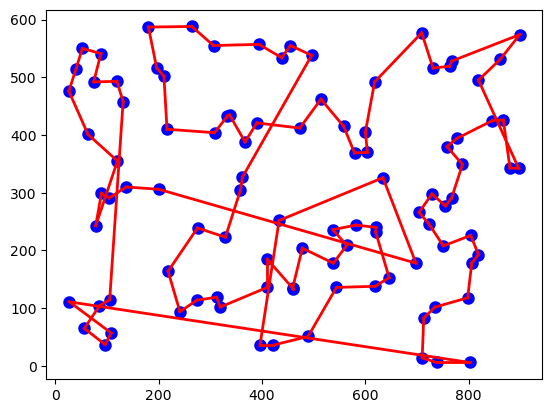

######### VMP Completa #########
Tempo de execução: 0.067532 s
Tamanho =  6374.469283778897


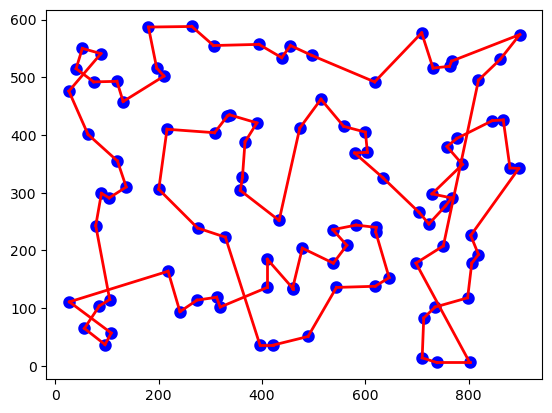

######### VMP Amostral #########
Tempo de execução: 0.006616 s
Tamanho =  6445.842850354659


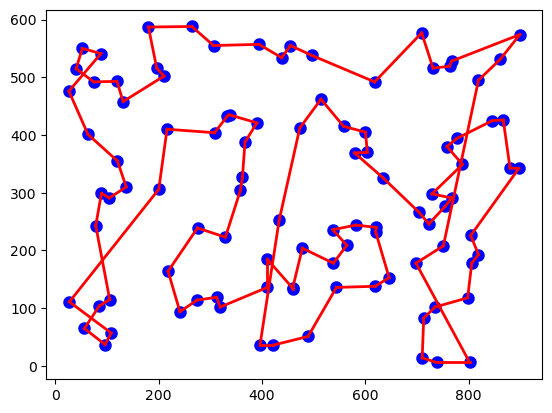

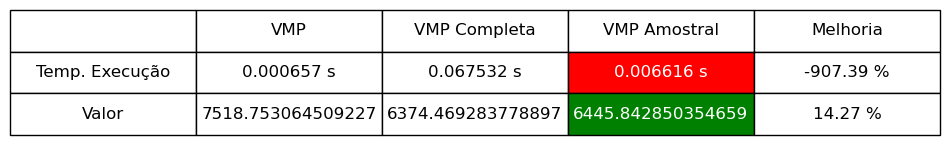

In [81]:
# Teste para 100 cidades

comparador(cidades100, proporcao_padrao, rseed_padrao)

######### VMP #########
Tempo de execução: 0.002704 s
Tamanho =  9889.697620363442


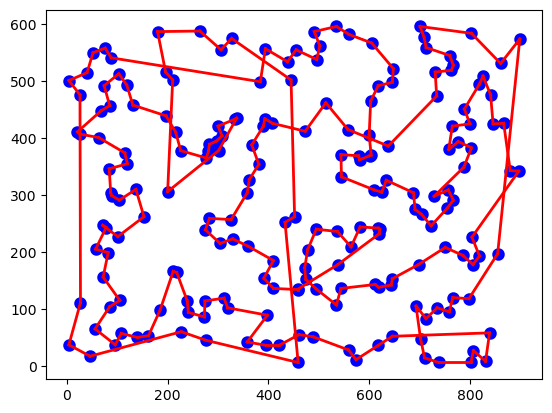

######### VMP Completa #########
Tempo de execução: 0.513538 s
Tamanho =  9348.6722200493


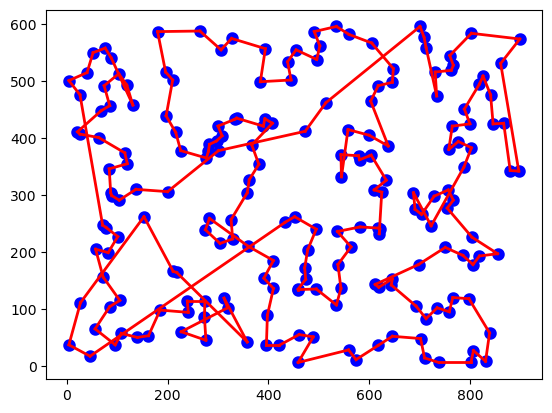

######### VMP Amostral #########
Tempo de execução: 0.059635 s
Tamanho =  9523.211432993769


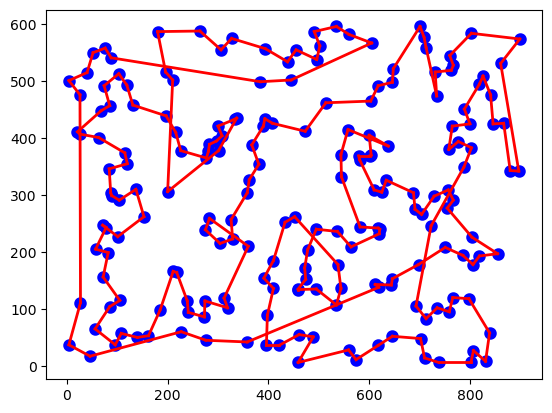

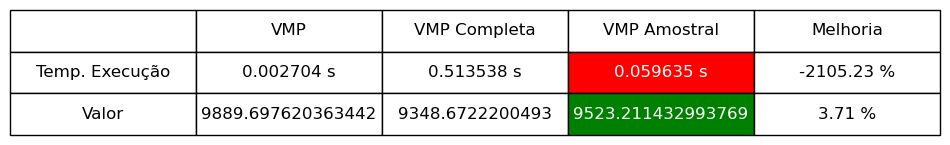

In [82]:
# Teste para 200 cidades

comparador(cidades200, proporcao_padrao, rseed_padrao)

######### VMP #########
Tempo de execução: 0.016065 s
Tamanho =  15224.965717151807


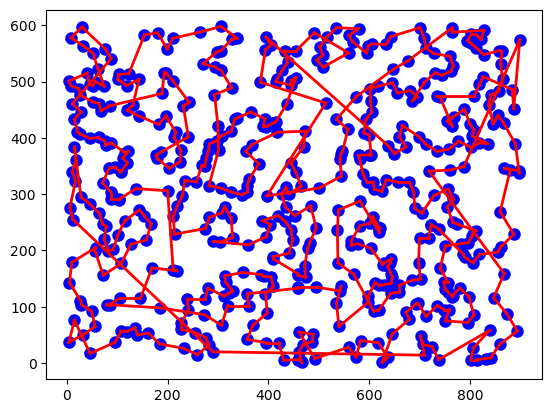

######### VMP Completa #########
Tempo de execução: 7.765024 s
Tamanho =  15010.621653924673


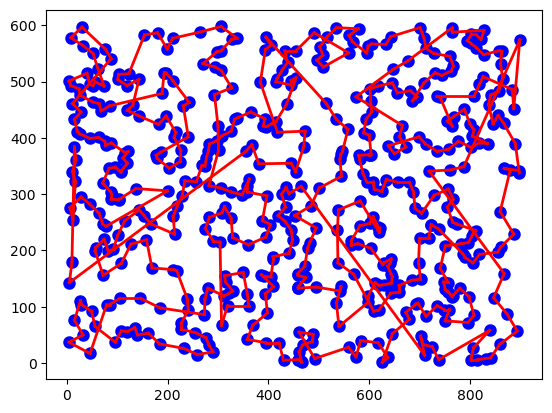

######### VMP Amostral #########
Tempo de execução: 0.777838 s
Tamanho =  15054.287197130494


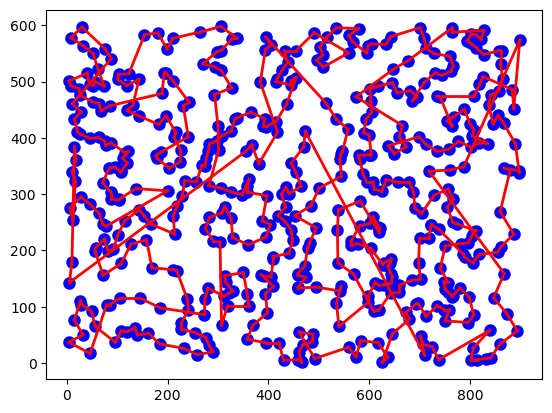

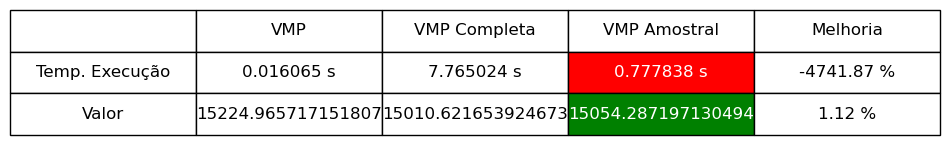

In [83]:
# Teste para 500 cidades

comparador(cidades500, proporcao_padrao, rseed_padrao)

# Exercício 1 - Discussões

1. Quanto ganhamos em qualidade utilizando vários pontos iniciais?
2. O ganho aumenta proporcionalmente ao número de pontos iniciais utilizados?
3. O aumento do custo computacional é compensado pela melhoria da solução?
4. Uma amostra de 10% parece suficiente? Experimente também outras proporções.

Levando uma proporção de 10% em consideração, o ganho de qualidade no resultado final na maioria dos testes não supera 5% quando comparado com o algoritimo de VMP, com execeção dos testes com 100 cidades, neles o aumento de qualidade pode passar de 10%.

Dito isso, em todos casos, o valor da solução se aproxima do resultado da função VMP Completa em consideravelmente menos tempo quando comparado com o tempo de execução da mesma, podendo justificar seu uso em alguns casos.

## Exercício 2 — Heurística de inserção mais barata

Implemente uma nova heurística construtiva para o PCV baseada em **inserção mais barata**.

Considere uma rota parcial contendo uma aresta $(i,j)$. Se desejarmos inserir uma cidade $k$ entre $i$ e $j$, o aumento no custo da rota será

$$
\Delta(i,k,j)
=
d(i,k)+d(k,j)-d(i,j).
$$

A heurística deve funcionar da seguinte maneira:

1. construa uma pequena rota inicial;
2. considere todas as cidades que ainda não pertencem à rota;
3. para cada cidade $k$, considere todas as possíveis posições de inserção;
4. escolha a combinação $(i,k,j)$ que produz o menor aumento de custo $\Delta(i,k,j)$;
5. insira a cidade escolhida na rota;
6. repita o procedimento até que todas as cidades tenham sido inseridas.

Implemente uma função

```python
insercao_mais_barata(cidades)
```

que retorne a rota construída.

Compare essa heurística com:

* `vizinho_mais_proximo`;
* `guloso`.

Para uma mesma instância, desenhe as rotas obtidas pelos três métodos e compare seus custos.

**Questões para discussão:**

1. Qual dos métodos produz a melhor solução?
2. A resposta é sempre a mesma para diferentes instâncias?
3. Que diferença existe entre a decisão gulosa tomada pelo vizinho mais próximo e aquela tomada pela inserção mais barata?
4. É possível identificar visualmente decisões ruins tomadas durante a construção das rotas?

---

## Exercício 3 — Construção seguida de busca local 2-opt

Neste exercício queremos investigar quanto a escolha da solução inicial influencia o resultado de uma busca local.

Considere as seguintes heurísticas construtivas:

* vizinho mais próximo;
* vizinho mais próximo com múltiplos pontos iniciais;
* heurística gulosa;
* inserção mais barata;
* heurística baseada em árvore geradora mínima.

Para cada método:

1. construa uma solução inicial;
2. registre o seu custo;
3. aplique repetidamente o procedimento de melhoria 2-opt apresentado no notebook;
4. continue enquanto existir uma troca que melhore a solução;
5. registre o custo da solução final e o tempo de execução.

Organize os resultados em uma tabela semelhante a:

| Método construtivo        | Custo inicial | Custo após 2-opt | Melhoria (%) | Tempo |
| ------------------------- | ------------: | ---------------: | -----------: | ----: |
| Vizinho mais próximo      |               |                  |              |       |
| VMP com múltiplos inícios |               |                  |              |       |
| Guloso                    |               |                  |              |       |
| Inserção mais barata      |               |                  |              |       |
| AGM                       |               |                  |              |       |

A melhoria percentual pode ser calculada por

$$
100\times
\frac{z_{\text{inicial}}-z_{\text{final}}}
     {z_{\text{inicial}}}.
$$

Repita o experimento para diferentes instâncias.

**Questões para discussão:**

1. Qual heurística costuma produzir as melhores soluções iniciais?
2. Após a aplicação do 2-opt, as diferenças entre os métodos diminuem?
3. A melhor solução inicial sempre conduz à melhor solução final?
4. Duas soluções iniciais diferentes podem conduzir a mínimos locais diferentes?
5. A qualidade da solução inicial continua sendo importante quando utilizamos busca local?

---

## Exercício 4 (Pós-Graduação) — Heurística baseada em árvore geradora mínima

Uma possibilidade para construir uma rota do PCV consiste em utilizar uma **árvore geradora mínima (AGM)**.

O procedimento será composto pelas seguintes etapas:

1. construa uma árvore geradora mínima utilizando o algoritmo de Prim;
2. escolha uma cidade como raiz da árvore;
3. faça uma busca em profundidade a partir dessa raiz;
4. registre os vértices na ordem em que são visitados pela primeira vez;
5. utilize essa ordem para construir uma rota do PCV.

Complete a função

```python
preordem(adj, raiz=0)
```

e utilize-a na implementação

```python
agm_pcv(cidades, raiz=0)
```

já iniciada no notebook.

Experimente diferentes cidades como raiz da busca.

**Questões para discussão:**

1. A escolha da raiz altera a árvore geradora mínima?
2. A escolha da raiz altera a ordem de visitação dos vértices?
3. A escolha da raiz pode alterar o custo da rota produzida?
4. Seria interessante executar a heurística utilizando várias raízes e escolher a melhor solução?
5. Como essa estratégia se compara com `vizinho_mais_proximo`, `guloso` e `insercao_mais_barata`?



---

# Exercício 5 (Pós-Graduação) — Garantia de aproximação da heurística baseada em AGM

Considere agora o **PCV simétrico e métrico**, isto é, as distâncias satisfazem a desigualdade triangular:

$$
d(i,k) \leq d(i,j)+d(j,k).
$$

Seja $T$ uma árvore geradora mínima e seja $OPT$ o custo de uma rota ótima do PCV.

## Parte A — A AGM como limite inferior

Mostre que

$$
c(T)\leq OPT.
$$

**Dica:** considere uma rota ótima do PCV e retire uma de suas arestas. A estrutura resultante conecta todos os vértices e não contém ciclos.

---

## Parte B — Duplicando as arestas da árvore

Suponha que cada aresta da árvore geradora mínima seja percorrida duas vezes.

Mostre que o custo total desse percurso é

$$
2c(T).
$$

Utilizando o resultado da Parte A, conclua que

$$
2c(T)\leq 2OPT.
$$

Explique por que, após duplicar as arestas da árvore, é possível realizar um passeio fechado que percorra todas essas arestas.

---

## Parte C — Removendo visitas repetidas

O passeio obtido na etapa anterior pode visitar uma mesma cidade várias vezes.

Considere um trecho do percurso da forma

$$
i \rightarrow j \rightarrow k,
$$

em que a cidade $j$ já tenha sido visitada anteriormente.

Utilizando a desigualdade triangular,

$$
d(i,k)\leq d(i,j)+d(j,k),
$$

mostre que podemos substituir esse trecho por

$$
i \rightarrow k
$$

sem aumentar o custo do passeio.

Aplicando sucessivamente esse procedimento, mostre que podemos obter uma rota que visita cada cidade exatamente uma vez.

Conclua que a rota $H$ produzida dessa forma satisfaz

$$
c(H)\leq 2OPT.
$$

---

## Parte D — Verificação computacional

Implemente a heurística baseada na AGM e, para pequenas instâncias nas quais ainda seja possível determinar a solução ótima por força bruta, calcule

$$
\rho =
\frac{c(H)}{OPT}.
$$

Realize o experimento para várias instâncias aleatórias e verifique empiricamente se

$$
\rho \leq 2.
$$

Compare também os valores de

$$
\frac{c(S)}{OPT}
$$

para as soluções produzidas por:

* vizinho mais próximo;
* heurística gulosa;
* inserção mais barata;
* heurística baseada em AGM.

Organize os resultados em uma tabela.

---

## Parte E — Discussão

Responda às seguintes questões:

1. Qual é a diferença entre observar empiricamente que uma heurística produz boas soluções e demonstrar matematicamente uma garantia de qualidade?
2. O fato de a heurística baseada em AGM possuir garantia

$$
c(H)\leq2OPT
$$

significa que ela produzirá soluções melhores do que as demais heurísticas nas instâncias testadas?

3. Podemos obter experimentalmente valores de $\rho$ muito menores que 2 mesmo que a garantia teórica seja igual a 2?
4. Qual é a importância de uma garantia de aproximação quando não conhecemos a solução ótima do problema?
5. Como os resultados experimentais se relacionam com o pior caso previsto pela análise teórica?

---

## Para refletir

Os experimentos anteriores ilustram três componentes que aparecerão repetidamente ao longo da disciplina:

1. **Construção:** gerar rapidamente uma solução viável;
2. **Vizinhança:** definir pequenas modificações que podem ser aplicadas a uma solução;
3. **Busca local:** explorar a vizinhança procurando soluções melhores.

Uma estratégia simples passa, portanto, a ter a forma

$$
\text{Construção}
\quad\longrightarrow\quad
\text{Solução inicial}
\quad\longrightarrow\quad
\text{Busca local}
\quad\longrightarrow\quad
\text{Ótimo local}.
$$

Nas próximas etapas da disciplina veremos como as **metaheurísticas** modificam esse processo para permitir maior diversificação da busca e, principalmente, reduzir a dependência do ótimo local encontrado.
